# DSC 411/511
# Logistic Regression, SVM, and Model Evaluation


---
# Section 0: Setup and the Two Targets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score, precision_recall_curve)

sns.set_style('whitegrid')
SEED = 42
print('ready')

ready


In [2]:
DATA_path= "/Users/home/workspace/School/DataMining/DataMining/class_workbooks/datasets/AmesHousing.csv"

df = pd.read_csv(DATA_path)

print('Rows:', df.shape[0])
print('Columns:', df.shape[1])

Rows: 2930
Columns: 82


In [3]:
# TARGET A: above or below the median. Balanced.
median_price = df['SalePrice'].median()
df['Expensive'] = (df['SalePrice'] > median_price).astype(int)

# TARGET B: luxury, top 10 percent. Imbalanced.
lux_cut = df['SalePrice'].quantile(0.90)
df['Luxury'] = (df['SalePrice'] > lux_cut).astype(int)

print(f'Median price      : ${median_price:>9,.0f}')
print(f'Luxury cut (90th) : ${lux_cut:>9,.0f}')
print()
for col in ['Expensive', 'Luxury']:
    n1 = int(df[col].sum()); n0 = len(df) - n1
    print(f'{col:<10} class 1: {n1:>5,} ({n1/len(df)*100:>4.1f}%)   '
          f'class 0: {n0:>5,} ({n0/len(df)*100:>4.1f}%)')

Median price      : $  160,000
Luxury cut (90th) : $  281,242

Expensive  class 1: 1,463 (49.9%)   class 0: 1,467 (50.1%)
Luxury     class 1:   293 (10.0%)   class 0: 2,637 (90.0%)


In [4]:
DROP = ['Order', 'PID', 'SalePrice', 'Expensive', 'Luxury']
num = df.select_dtypes(include='number').drop(columns=[c for c in DROP if c in df.columns])

X  = num.fillna(num.median())
yA = df['Expensive']
yB = df['Luxury']

print('Features:', X.shape[1])
print('SalePrice in X?', 'SalePrice' in X.columns, ' <- must be False')

Features: 36
SalePrice in X? False  <- must be False


In [5]:
Xtr, Xte, ytr, yte = train_test_split(X, yA, test_size=0.25,
                                      random_state=SEED, stratify=yA)

scaler = StandardScaler().fit(Xtr)        # fit on TRAIN only
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

baseline = max(yte.mean(), 1 - yte.mean())
print(f'Train rows : {len(Xtr):,}')
print(f'Test rows  : {len(Xte):,}')
print(f'Baseline   : {baseline*100:.1f}%')

Train rows : 2,197
Test rows  : 733
Baseline   : 50.1%


---
# Section 1: Logistic Regression

Add up every column with a weight, then squash the result into a probability.

In [6]:
logreg = LogisticRegression(max_iter=3000, random_state=SEED)
logreg.fit(Xtr_s, ytr)

acc_lr = accuracy_score(yte, logreg.predict(Xte_s))
print(f'Logistic regression : {acc_lr*100:.1f}%')
print(f'Baseline            : {baseline*100:.1f}%')

Logistic regression : 92.0%
Baseline            : 50.1%


## 1.1 The equation, with real numbers

This is the `z` from the slides, built from your own data.

In [7]:
coefs = pd.Series(logreg.coef_[0], index=X.columns)
a0 = logreg.intercept_[0]

top = coefs.abs().sort_values(ascending=False).head(6).index
print(f'z  =  {a0:+.3f}')
for c in top:
    print(f'      {coefs[c]:+.3f} x {c}')
print(f'      ... and {X.shape[1] - len(top)} more terms')

z  =  +0.368
      +1.307 x Overall Qual
      +1.157 x Year Built
      +0.880 x Garage Cars
      +0.842 x Gr Liv Area
      +0.669 x 2nd Flr SF
      +0.637 x Full Bath
      ... and 30 more terms


## 1.2 One house, traced end to end

In [8]:
i = 0
row = Xte_s[i]
z = a0 + row @ logreg.coef_[0]
p = 1 / (1 + np.exp(-z))

print('STEP 1: the weighted sum')
print(f'   z = {z:.4f}')
print()
print('STEP 2: through the sigmoid')
print(f'   p = 1 / (1 + e^(-{z:.4f}))')
print(f'     = 1 / (1 + {np.exp(-z):.4f})')
print(f'     = {p:.4f}')
print()
print('STEP 3: threshold at 0.5')
print(f'   prediction : {"Above median" if p > .5 else "Below median"}')
print(f'   truth      : {"Above median" if yte.iloc[i] == 1 else "Below median"}')
print()
print(f'sklearn agrees: {logreg.predict_proba(Xte_s[[i]])[0,1]:.4f}')

STEP 1: the weighted sum
   z = -6.3000

STEP 2: through the sigmoid
   p = 1 / (1 + e^(--6.3000))
     = 1 / (1 + 544.5475)
     = 0.0018

STEP 3: threshold at 0.5
   prediction : Below median
   truth      : Below median

sklearn agrees: 0.0018


## 1.3 The sigmoid, drawn on your own predictions

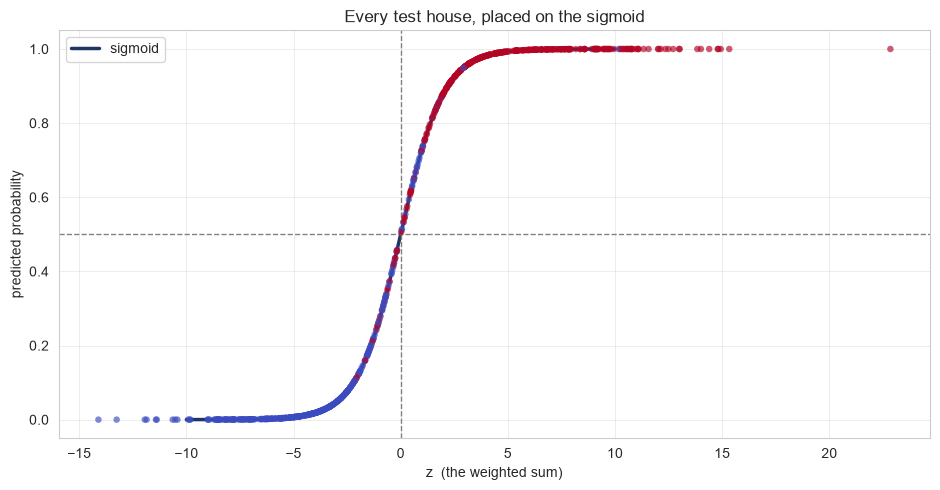

Blue points are houses below the median. Red are above.
They line up on the curve because the curve IS the model.
z = 0 corresponds to p = 0.5, which is the decision boundary.


In [9]:
z_all = a0 + Xte_s @ logreg.coef_[0]
p_all = logreg.predict_proba(Xte_s)[:, 1]

zz = np.linspace(-10, 10, 400)
plt.figure(figsize=(9.5, 5))
plt.plot(zz, 1/(1+np.exp(-zz)), color='#1F3564', lw=2.5, label='sigmoid')
plt.scatter(z_all, p_all, c=yte, cmap='coolwarm', s=22, alpha=.65,
            edgecolors='none', zorder=3)
plt.axhline(0.5, color='grey', ls='--', lw=1)
plt.axvline(0, color='grey', ls='--', lw=1)
plt.xlabel('z  (the weighted sum)'); plt.ylabel('predicted probability')
plt.title('Every test house, placed on the sigmoid')
plt.legend(); plt.tight_layout(); plt.show()

print('Blue points are houses below the median. Red are above.')
print('They line up on the curve because the curve IS the model.')
print(f'z = 0 corresponds to p = 0.5, which is the decision boundary.')

---
# Section 2: Reading the Coefficients

The only model today that tells you **why**.

In [10]:
srt = coefs.reindex(coefs.abs().sort_values(ascending=False).index)

print('TEN LARGEST COEFFICIENTS')
print(f"{'column':24}{'coef':>10}   direction")
for c in srt.head(10).index:
    d = 'pushes toward ABOVE median' if coefs[c] > 0 else 'pushes toward BELOW median'
    print(f'{c:24}{coefs[c]:>+10.3f}   {d}')

TEN LARGEST COEFFICIENTS
column                        coef   direction
Overall Qual                +1.307   pushes toward ABOVE median
Year Built                  +1.157   pushes toward ABOVE median
Garage Cars                 +0.880   pushes toward ABOVE median
Gr Liv Area                 +0.842   pushes toward ABOVE median
2nd Flr SF                  +0.669   pushes toward ABOVE median
Full Bath                   +0.637   pushes toward ABOVE median
Fireplaces                  +0.612   pushes toward ABOVE median
Overall Cond                +0.595   pushes toward ABOVE median
Kitchen AbvGr               -0.541   pushes toward BELOW median
Lot Area                    +0.494   pushes toward ABOVE median


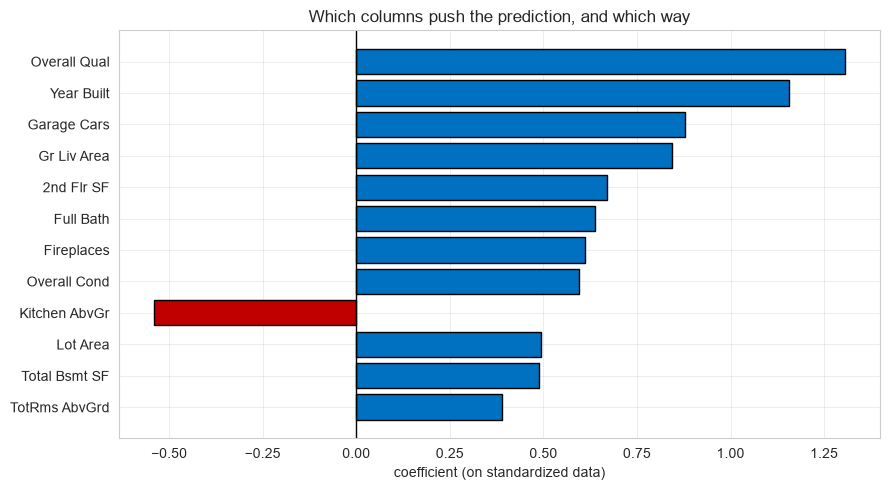

In [11]:
plt.figure(figsize=(9, 5))
top12 = srt.head(12).iloc[::-1]
cols = ['#C00000' if v < 0 else '#0070C0' for v in top12]
plt.barh(range(len(top12)), top12.values, color=cols, edgecolor='black')
plt.yticks(range(len(top12)), top12.index)
plt.axvline(0, color='black', lw=1)
plt.xlabel('coefficient (on standardized data)')
plt.title('Which columns push the prediction, and which way')
plt.tight_layout(); plt.show()

### Why scaling matters for reading these

A coefficient means "change in z per one unit of x". But one unit of `Lot Area`
is one square foot, and one unit of `Overall Qual` is a whole quality grade.

On raw data the coefficients are measuring the units, not the importance.
On standardized data one unit is one standard deviation everywhere, so they compare.

In [12]:
# Prove it. Fit on raw data and compare the ranking.
# Unscaled data makes the solver struggle, which is itself the lesson.
import warnings
warnings.filterwarnings('ignore', category=UserWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

lr_raw = LogisticRegression(max_iter=5000, random_state=SEED).fit(Xtr, ytr)
raw_c = pd.Series(lr_raw.coef_[0], index=X.columns)

cmp = pd.DataFrame({
    'raw rank'   : raw_c.abs().rank(ascending=False).astype(int),
    'scaled rank': coefs.abs().rank(ascending=False).astype(int),
}).loc[srt.head(8).index]
print('Where each column ranks, by coefficient size:')
print(cmp.to_string())
print()
print('Different rankings. Only the scaled one is meaningful.')
print('The SIGN is the same either way. Sign never depends on units.')

Where each column ranks, by coefficient size:
              raw rank  scaled rank
Overall Qual         1            1
Year Built          10            2
Garage Cars          4            3
Gr Liv Area         18            4
2nd Flr SF          25            5
Full Bath            5            6
Fireplaces           2            7
Overall Cond         3            8

Different rankings. Only the scaled one is meaningful.
The SIGN is the same either way. Sign never depends on units.


---
# Section 3: Support Vector Machine

Find the widest gap between the two groups.

In [13]:
svm_lin = SVC(kernel='linear', random_state=SEED).fit(Xtr_s, ytr)
svm_rbf = SVC(kernel='rbf',    random_state=SEED).fit(Xtr_s, ytr)

print(f'SVM, linear kernel : {accuracy_score(yte, svm_lin.predict(Xte_s))*100:.1f}%')
print(f'SVM, RBF kernel    : {accuracy_score(yte, svm_rbf.predict(Xte_s))*100:.1f}%')
print(f'Logistic regression: {acc_lr*100:.1f}%')
print(f'Baseline           : {baseline*100:.1f}%')

SVM, linear kernel : 92.6%
SVM, RBF kernel    : 92.9%
Logistic regression: 92.0%
Baseline           : 50.1%


In [14]:
# SVM on UNSCALED data. Same lesson as k-NN.
t0 = time.perf_counter()
svm_raw = SVC(kernel='rbf', random_state=SEED).fit(Xtr, ytr)
t_raw = time.perf_counter() - t0

print(f'SVM (RBF) on raw data    : {accuracy_score(yte, svm_raw.predict(Xte))*100:.1f}%')
print(f'SVM (RBF) on scaled data : {accuracy_score(yte, svm_rbf.predict(Xte_s))*100:.1f}%')
print()
print('SVM compares columns against each other, exactly like k-NN.')
print('Without scaling, Lot Area decides the boundary on its own.')

SVM (RBF) on raw data    : 82.3%
SVM (RBF) on scaled data : 92.9%

SVM compares columns against each other, exactly like k-NN.
Without scaling, Lot Area decides the boundary on its own.


---
# Section 4: Who Actually Decided the Boundary?

In [15]:
n_sv = int(svm_lin.n_support_.sum())
print(f'Training houses      : {len(Xtr):,}')
print(f'Support vectors      : {n_sv:,}')
print(f'Percentage that mattered : {n_sv/len(Xtr)*100:.1f}%')
print()
print(f'The other {len(Xtr)-n_sv:,} houses could be deleted and the boundary would not move.')

Training houses      : 2,197
Support vectors      : 414
Percentage that mattered : 18.8%

The other 1,783 houses could be deleted and the boundary would not move.


In [16]:
# Prove it: refit using only the support vectors
sv_idx = svm_lin.support_
m2 = SVC(kernel='linear', random_state=SEED).fit(Xtr_s[sv_idx], ytr.iloc[sv_idx])

print(f'Full training set  : {accuracy_score(yte, svm_lin.predict(Xte_s))*100:.2f}%')
print(f'Support vectors only: {accuracy_score(yte, m2.predict(Xte_s))*100:.2f}%')
print()
agree = (svm_lin.predict(Xte_s) == m2.predict(Xte_s)).mean()
print(f'The two models agree on {agree*100:.1f}% of test predictions.')
print()
print('That is the whole idea of SVM. Points far from the boundary contribute nothing.')

Full training set  : 92.63%
Support vectors only: 92.63%

The two models agree on 100.0% of test predictions.

That is the whole idea of SVM. Points far from the boundary contribute nothing.


---
# Section 5: All Five Models on Question A

In [17]:
MODELS = {
    'Decision tree (d=5)'  : (DecisionTreeClassifier(max_depth=5, random_state=SEED), False),
    'Naive Bayes'          : (GaussianNB(), False),
    'k-NN (k=21)'          : (KNeighborsClassifier(n_neighbors=21), True),
    'Logistic regression'  : (LogisticRegression(max_iter=3000, random_state=SEED), True),
    'SVM (RBF)'            : (SVC(kernel='rbf', probability=True, random_state=SEED), True),
}

rows = []
fitted = {}
for name, (mdl, scale) in MODELS.items():
    A, B = (Xtr_s, Xte_s) if scale else (Xtr.values, Xte.values)
    t0 = time.perf_counter(); mdl.fit(A, ytr); t_fit = time.perf_counter() - t0
    fitted[name] = (mdl, scale)
    rows.append({'model': name, 'scaled': 'yes' if scale else 'no',
                 'test acc': round(accuracy_score(yte, mdl.predict(B))*100, 1),
                 'fit time (s)': round(t_fit, 3)})

comp = pd.DataFrame(rows)
print(f'Baseline: {baseline*100:.1f}%')
print()
print(comp.to_string(index=False))

/Users/home/.conda/envs/handsonml/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Baseline: 50.1%

              model scaled  test acc  fit time (s)
Decision tree (d=5)     no      91.3         0.009
        Naive Bayes     no      91.1         0.001
        k-NN (k=21)    yes      90.7         0.000
Logistic regression    yes      92.0         0.004
          SVM (RBF)    yes      92.9         0.218


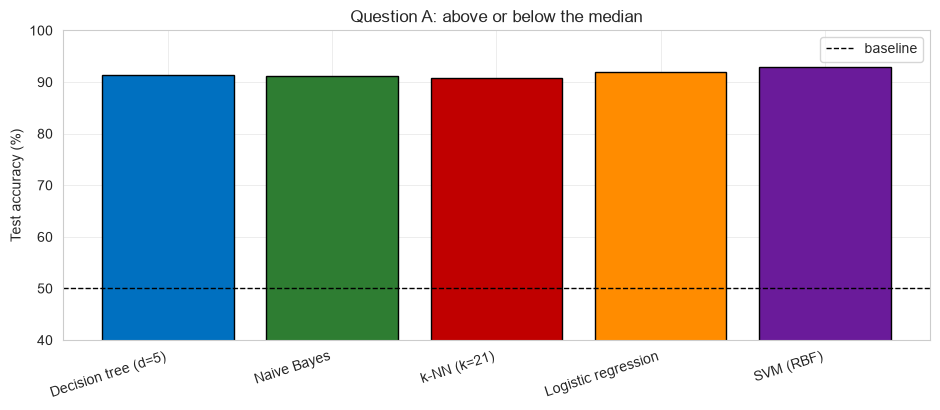

In [18]:
plt.figure(figsize=(9.5, 4.2))
plt.bar(comp['model'], comp['test acc'],
        color=['#0070C0','#2E7D32','#C00000','#FF8C00','#6A1B9A'], edgecolor='black')
plt.axhline(baseline*100, color='black', ls='--', lw=1, label='baseline')
plt.ylabel('Test accuracy (%)'); plt.ylim(40, 100)
plt.xticks(rotation=18, ha='right')
plt.title('Question A: above or below the median')
plt.legend(); plt.tight_layout(); plt.show()

---
# Section 6: Why Accuracy Is Not Enough

Switch to **Question B**. Is this a luxury property? Top 10 percent of prices.

In [19]:
XtrB, XteB, ytrB, yteB = train_test_split(X, yB, test_size=0.25,
                                          random_state=SEED, stratify=yB)
scB = StandardScaler().fit(XtrB)
XtrB_s, XteB_s = scB.transform(XtrB), scB.transform(XteB)

baseB = max(yteB.mean(), 1 - yteB.mean())
print(f'Luxury houses in the test set : {int(yteB.sum())} of {len(yteB)}')
print(f'Baseline accuracy             : {baseB*100:.1f}%')

Luxury houses in the test set : 73 of 733
Baseline accuracy             : 90.0%


In [20]:
# The laziest possible model. Predicts "not luxury" for everything.
lazy = np.zeros(len(yteB), dtype=int)

print('THE LAZY MODEL')
print(f'   accuracy : {accuracy_score(yteB, lazy)*100:.1f}%')
print(f'   recall on luxury : {recall_score(yteB, lazy, zero_division=0)*100:.1f}%')
print()
print('It reads no columns. It found zero luxury houses.')
print('And it beats a lot of real models on accuracy.')
print()
print('Confusion matrix:')
print(pd.DataFrame(confusion_matrix(yteB, lazy),
                   index=['actually not luxury','actually luxury'],
                   columns=['predicted not luxury','predicted luxury']))

THE LAZY MODEL
   accuracy : 90.0%
   recall on luxury : 0.0%

It reads no columns. It found zero luxury houses.
And it beats a lot of real models on accuracy.

Confusion matrix:
                     predicted not luxury  predicted luxury
actually not luxury                   660                 0
actually luxury                        73                 0


In [21]:
# A real model on the same question
lrB = LogisticRegression(max_iter=3000, random_state=SEED).fit(XtrB_s, ytrB)
predB = lrB.predict(XteB_s)

print('LOGISTIC REGRESSION ON THE SAME QUESTION')
print(f'   accuracy          : {accuracy_score(yteB, predB)*100:.1f}%')
print(f'   recall on luxury  : {recall_score(yteB, predB)*100:.1f}%')
print(f'   precision on luxury: {precision_score(yteB, predB, zero_division=0)*100:.1f}%')
print()
print(f'Lazy model accuracy : {accuracy_score(yteB, lazy)*100:.1f}%')
print()
print('Compare the accuracies. Then compare the recalls. Only one of those is informative.')

LOGISTIC REGRESSION ON THE SAME QUESTION
   accuracy          : 96.2%
   recall on luxury  : 80.8%
   precision on luxury: 80.8%

Lazy model accuracy : 90.0%

Compare the accuracies. Then compare the recalls. Only one of those is informative.


---
# Section 7: Confusion Matrix, Precision, Recall, F1

In [22]:
cm = confusion_matrix(yteB, predB)
tn, fp, fn, tp = cm.ravel()

print('THE FOUR CELLS, IN PLAIN LANGUAGE')
print(f'   True Negative  = {tn:>4}   ordinary house, correctly called ordinary')
print(f'   False Positive = {fp:>4}   we flagged an ordinary house. Wasted site visit')
print(f'   False Negative = {fn:>4}   luxury house we missed. Undervalued, sold too cheap')
print(f'   True Positive  = {tp:>4}   luxury house, correctly spotted')
print()
print('THE METRICS, COMPUTED BY HAND')
print(f'   Accuracy  = ({tp} + {tn}) / {len(yteB)}          = {(tp+tn)/len(yteB):.4f}')
print(f'   Precision = {tp} / ({tp} + {fp})  = {tp/(tp+fp) if tp+fp else 0:.4f}')
print(f'   Recall    = {tp} / ({tp} + {fn})  = {tp/(tp+fn) if tp+fn else 0:.4f}')
prec = tp/(tp+fp) if tp+fp else 0
rec  = tp/(tp+fn) if tp+fn else 0
print(f'   F1        = 2 x ({prec:.3f} x {rec:.3f}) / ({prec:.3f} + {rec:.3f}) '
      f'= {2*prec*rec/(prec+rec) if prec+rec else 0:.4f}')

THE FOUR CELLS, IN PLAIN LANGUAGE
   True Negative  =  646   ordinary house, correctly called ordinary
   False Positive =   14   we flagged an ordinary house. Wasted site visit
   False Negative =   14   luxury house we missed. Undervalued, sold too cheap
   True Positive  =   59   luxury house, correctly spotted

THE METRICS, COMPUTED BY HAND
   Accuracy  = (59 + 646) / 733          = 0.9618
   Precision = 59 / (59 + 14)  = 0.8082
   Recall    = 59 / (59 + 14)  = 0.8082
   F1        = 2 x (0.808 x 0.808) / (0.808 + 0.808) = 0.8082


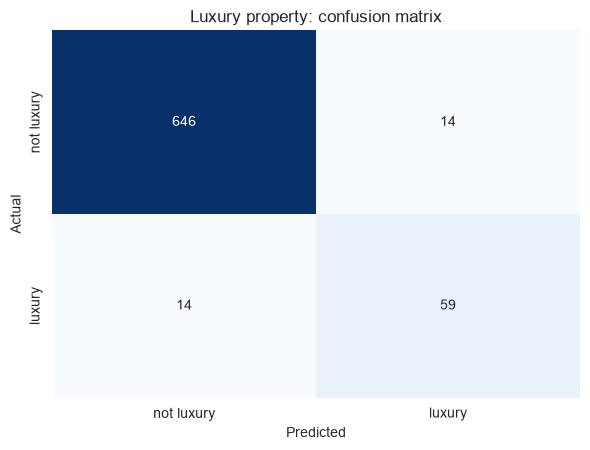

              precision    recall  f1-score   support

  not luxury       0.98      0.98      0.98       660
      luxury       0.81      0.81      0.81        73

    accuracy                           0.96       733
   macro avg       0.89      0.89      0.89       733
weighted avg       0.96      0.96      0.96       733



In [23]:
plt.figure(figsize=(6, 4.6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['not luxury','luxury'], yticklabels=['not luxury','luxury'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Luxury property: confusion matrix')
plt.tight_layout(); plt.show()

print(classification_report(yteB, predB, target_names=['not luxury','luxury'],
                            zero_division=0))

In [24]:
# Why F1 rather than a plain average
print('If precision = 1.0 and recall = 0.0:')
print(f'   plain average = {(1.0 + 0.0)/2:.2f}   <- looks acceptable')
print(f'   F1            = {2*1.0*0.0/(1.0+0.0+1e-12):.2f}   <- correctly brutal')
print()
print('F1 punishes you for being bad at either one.')

If precision = 1.0 and recall = 0.0:
   plain average = 0.50   <- looks acceptable
   F1            = 0.00   <- correctly brutal

F1 punishes you for being bad at either one.


---
# Section 8: Moving the Threshold

In [32]:
proba = lrB.predict_proba(XteB_s)[:, 1]

rows = []
for t in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    pr = (proba >= t).astype(int)
    rows.append({'threshold': t,
                 'flagged as luxury': int(pr.sum()),
                 'precision': round(precision_score(yteB, pr, zero_division=0), 3),
                 'recall'   : round(recall_score(yteB, pr, zero_division=0), 3),
                 'F1'       : round(f1_score(yteB, pr, zero_division=0), 3),
                 'accuracy' : round(accuracy_score(yteB, pr), 3)})
th = pd.DataFrame(rows)
print(th.to_string(index=False))
print()
print('Read down the precision and recall columns. They move in opposite directions.')
best_t = th.loc[th['F1'].idxmax(), 'F1']

 threshold  flagged as luxury  precision  recall    F1  accuracy
      0.05                144      0.500   0.986 0.664     0.900
      0.10                122      0.590   0.986 0.738     0.930
      0.20                106      0.623   0.904 0.737     0.936
      0.30                 92      0.674   0.849 0.752     0.944
      0.50                 73      0.808   0.808 0.808     0.962
      0.70                 57      0.912   0.712 0.800     0.965
      0.90                 37      1.000   0.507 0.673     0.951

Read down the precision and recall columns. They move in opposite directions.


---
# Section 9: ROC and AUC

/Users/home/.conda/envs/handsonml/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


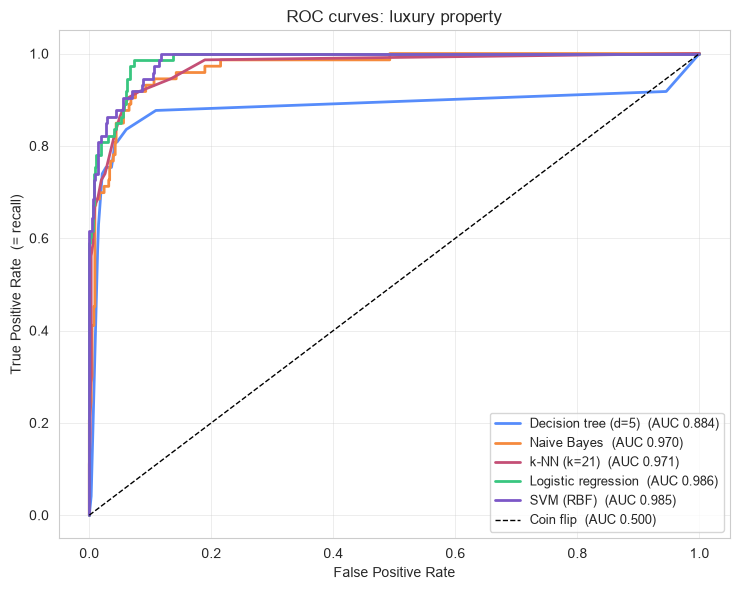

In [26]:
plt.figure(figsize=(7.5, 6))

for name, (mdl, scale) in fitted.items():
    A = XteB_s if scale else XteB.values
    Atr = XtrB_s if scale else XtrB.values
    try:
        m = mdl.__class__(**mdl.get_params()).fit(Atr, ytrB)
        p = m.predict_proba(A)[:, 1]
    except Exception:
        continue
    fpr, tpr, _ = roc_curve(yteB, p)
    plt.plot(fpr, tpr, lw=2, label=f'{name}  (AUC {roc_auc_score(yteB, p):.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Coin flip  (AUC 0.500)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate  (= recall)')
plt.title('ROC curves: luxury property')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

### How to read it

- **Up and to the left is better.** High recall, few false alarms.
- The **diagonal** is a coin flip. Anything on it has learned nothing.
- **AUC** is the area under the curve. 1.0 perfect, 0.5 useless.
- Each point on a curve is **one threshold**. The whole curve is every threshold at once.

**One honest caveat.** On badly imbalanced data ROC can look flattering, because
the False Positive Rate has a huge denominator. A precision-recall curve is stricter.

---
# Section 10: Cross-Validation

In [27]:
print('ONE SPLIT IS NOT EVIDENCE. Change the seed and watch.')
print()
for s in [0, 1, 7, 42, 99]:
    a, b, c, d = train_test_split(X, yA, test_size=0.25, random_state=s, stratify=yA)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    pipe.fit(a, c)
    print(f'   seed {s:>3}: {accuracy_score(d, pipe.predict(b))*100:.1f}%')

ONE SPLIT IS NOT EVIDENCE. Change the seed and watch.

   seed   0: 91.8%
   seed   1: 92.1%
   seed   7: 92.4%
   seed  42: 92.0%
   seed  99: 92.9%


In [28]:
rows = []
for name, (mdl, scale) in MODELS.items():
    pipe = make_pipeline(StandardScaler(), mdl.__class__(**mdl.get_params())) if scale \
           else mdl.__class__(**mdl.get_params())
    s = cross_val_score(pipe, X, yA, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    rows.append({'model': name,
                 'CV mean': round(s.mean()*100, 1),
                 'CV std' : round(s.std()*100, 2),
                 'worst fold': round(s.min()*100, 1),
                 'best fold' : round(s.max()*100, 1)})
cv = pd.DataFrame(rows).sort_values('CV mean', ascending=False)
print(cv.to_string(index=False))
print()
print('Report the standard deviation, not just the mean.')
top2 = cv.head(2)
gap = top2['CV mean'].iloc[0] - top2['CV mean'].iloc[1]
sd  = top2['CV std'].max()
print(f'Top two models differ by {gap:.1f} points. Largest spread is {sd:.1f}.')
print('Tied.' if gap < sd else 'A real difference.')

/Users/home/.conda/envs/handsonml/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/home/.conda/envs/handsonml/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/home/.conda/envs/handsonml/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/home/.conda/envs/handsonml/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probab

              model  CV mean  CV std  worst fold  best fold
          SVM (RBF)     92.8    0.33        92.3       93.3
Logistic regression     92.5    0.34        92.0       93.0
        k-NN (k=21)     90.6    0.48        90.1       91.5
        Naive Bayes     89.7    0.84        88.7       90.8
Decision tree (d=5)     89.1    0.98        88.1       90.8

Report the standard deviation, not just the mean.
Top two models differ by 0.3 points. Largest spread is 0.3.
Tied.


### The pipeline is not optional

`make_pipeline(StandardScaler(), model)` refits the scaler inside every fold.

Scale first and then cross-validate, and each fold's scaler has already seen the
rows it is about to be tested on. The mean and standard deviation leaked.

---
# Section 11: Leakage

In [29]:
# LEAK 1: a column derived from the target
X_leak = X.copy()
X_leak['price_per_sqft'] = df['SalePrice'] / df['Gr Liv Area'].replace(0, np.nan)
X_leak = X_leak.fillna(X_leak.median())

a, b, c, d = train_test_split(X_leak, yA, test_size=0.25, random_state=SEED, stratify=yA)
leaky = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(a, c)

print('LEAK 1: a column built from the target')
print(f'   honest model : {acc_lr*100:.1f}%')
print(f'   leaky model  : {accuracy_score(d, leaky.predict(b))*100:.1f}%')
print()
print('price_per_sqft contains SalePrice. The model is reading the answer.')

LEAK 1: a column built from the target
   honest model : 92.0%
   leaky model  : 96.0%

price_per_sqft contains SalePrice. The model is reading the answer.


In [30]:
# LEAK 2: scaling before the split
bad_scaler = StandardScaler().fit(X)            # sees the whole dataset
X_all = bad_scaler.transform(X)
a, b, c, d = train_test_split(X_all, yA, test_size=0.25, random_state=SEED, stratify=yA)
m_bad = LogisticRegression(max_iter=3000, random_state=SEED).fit(a, c)

print('LEAK 2: scaling fitted on everything, before the split')
print(f'   correct order : {acc_lr*100:.1f}%')
print(f'   wrong order   : {accuracy_score(d, m_bad.predict(b))*100:.1f}%')
print()
print('The gap is usually small here, which is exactly why this one goes unnoticed.')
print('On smaller datasets it is much worse.')

LEAK 2: scaling fitted on everything, before the split
   correct order : 92.0%
   wrong order   : 92.0%

The gap is usually small here, which is exactly why this one goes unnoticed.
On smaller datasets it is much worse.


### The four ways leakage happens

1. **A column derived from the target.** `price_per_sqft` when predicting price.
2. **Preprocessing before the split.** Scaling or imputing using the whole dataset.
3. **Tuning on the test set.** Adjusting until the test score looks good.
4. **Time travel.** Using information that did not exist when the prediction was made.

**How to catch it:** if your accuracy is suspiciously high, look for leakage.
Do not celebrate.

---
# Section 12: Fixing Imbalance

In [33]:
plain    = LogisticRegression(max_iter=3000, random_state=SEED).fit(XtrB_s, ytrB)
weighted = LogisticRegression(max_iter=3000, random_state=SEED,
                              class_weight='balanced').fit(XtrB_s, ytrB)

rows = []
for name, m in [('default', plain), ("class_weight='balanced'", weighted)]:
    p = m.predict(XteB_s)
    rows.append({'model': name,
                 'accuracy' : round(accuracy_score(yteB, p)*100, 1),
                 'precision': round(precision_score(yteB, p, zero_division=0)*100, 1),
                 'recall'   : round(recall_score(yteB, p, zero_division=0)*100, 1),
                 'F1'       : round(f1_score(yteB, p, zero_division=0)*100, 1)})

# and the best-F1 threshold from Section 8
p_th = (proba >= best_t).astype(int)
rows.append({'model': f'threshold at {best_t:.2f}',
             'accuracy' : round(accuracy_score(yteB, p_th)*100, 1),
             'precision': round(precision_score(yteB, p_th, zero_division=0)*100, 1),
             'recall'   : round(recall_score(yteB, p_th, zero_division=0)*100, 1),
             'F1'       : round(f1_score(yteB, p_th, zero_division=0)*100, 1)})

imb = pd.DataFrame(rows)
print(f'Baseline accuracy: {baseB*100:.1f}%')
print()
print(imb.to_string(index=False))
print()
print('Read across. Accuracy may fall while recall rises sharply.')
print('Which one you want depends on what a missed luxury house costs you.')

Baseline accuracy: 90.0%

                  model  accuracy  precision  recall   F1
                default      96.2       80.8    80.8 80.8
class_weight='balanced'      93.5       60.5    98.6 75.0
      threshold at 0.81      95.8       97.7    58.9 73.5

Read across. Accuracy may fall while recall rises sharply.
Which one you want depends on what a missed luxury house costs you.


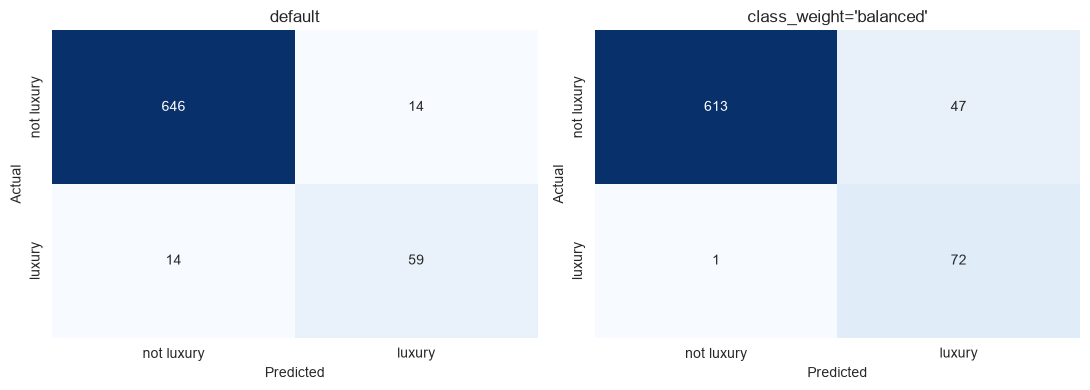

Bottom-left is the luxury houses you missed. Watch that cell shrink.
Top-right is the false alarms you took on to achieve it.


In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, m, name in [(ax[0], plain, 'default'), (ax[1], weighted, "class_weight='balanced'")]:
    sns.heatmap(confusion_matrix(yteB, m.predict(XteB_s)), annot=True, fmt='d',
                cmap='Blues', cbar=False, ax=a_,
                xticklabels=['not luxury','luxury'], yticklabels=['not luxury','luxury'])
    a_.set_xlabel('Predicted'); a_.set_ylabel('Actual'); a_.set_title(name)
plt.tight_layout(); plt.show()

print('Bottom-left is the luxury houses you missed. Watch that cell shrink.')
print('Top-right is the false alarms you took on to achieve it.')